In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

loans = pd.read_csv("../data/clean/loans_clean.csv")

In [12]:
loans["credit_score_category"] = pd.cut(
    loans["credit_score"],
    bins=[300,580,670,740,800,850],
    labels=["Poor","Fair","Good","Very Good","Excellent"],
    include_lowest=True
)

In [13]:
loan_summary = loans.groupby("loan_type").agg(
    total_loans=("loan_id", "count"),
    total_loan_amount=("loan_amount", "sum"),
    average_loan_amount=("loan_amount", "mean"),
    average_interest_rate=("interest_rate", "mean")
).round(2)

display(loan_summary.sort_values("total_loan_amount", ascending=False))

,total_loans,total_loan_amount,average_loan_amount,average_interest_rate
loan_type,,,,
Home Loan,10627,3209475000,302011.39,0.07
Business Loan,2962,417185000,140845.71,0.11
Car Loan,6082,231098000,37997.04,0.09
Personal Loan,7366,157016000,21316.32,0.12
Education Loan,2963,129802000,43807.63,0.08


,loan_count
loan_status,
Active,20948
Closed,8600
Defaulted,452


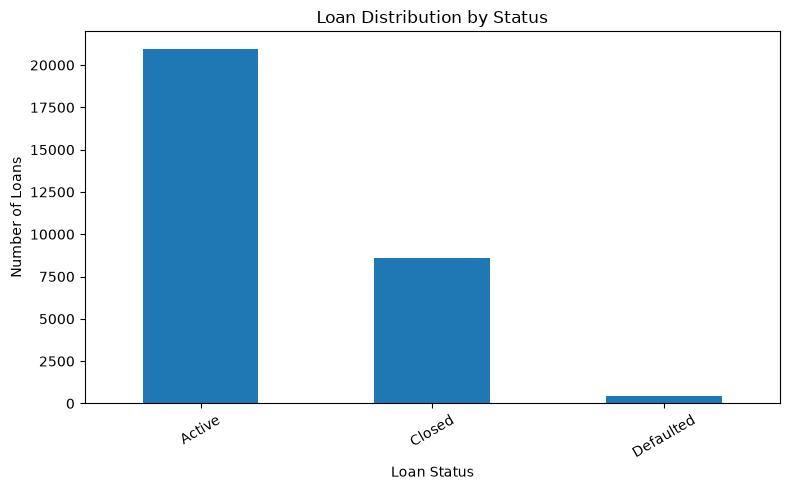

In [14]:
status_summary = loans["loan_status"].value_counts().to_frame("loan_count")

display(status_summary)

status_summary.plot(kind="bar", figsize=(8, 5), legend=False)
plt.title("Loan Distribution by Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

High Active Volume: Most loans are Active (~21,000), generating strong ongoing interest revenue.   
Solid Repayment History: A large portion of loans are successfully Closed (~8,600).   
Low Default Rate: Defaulted loans are extremely low (~400, or ~1.3%), showing effective credit risk management.   
Main Takeaway: Strong portfolio health allows the business to safely expand lending or target customers with closed loans for re-borrowing.  

,loan_count
loan_type,
Home Loan,10627
Personal Loan,7366
Car Loan,6082
Education Loan,2963
Business Loan,2962


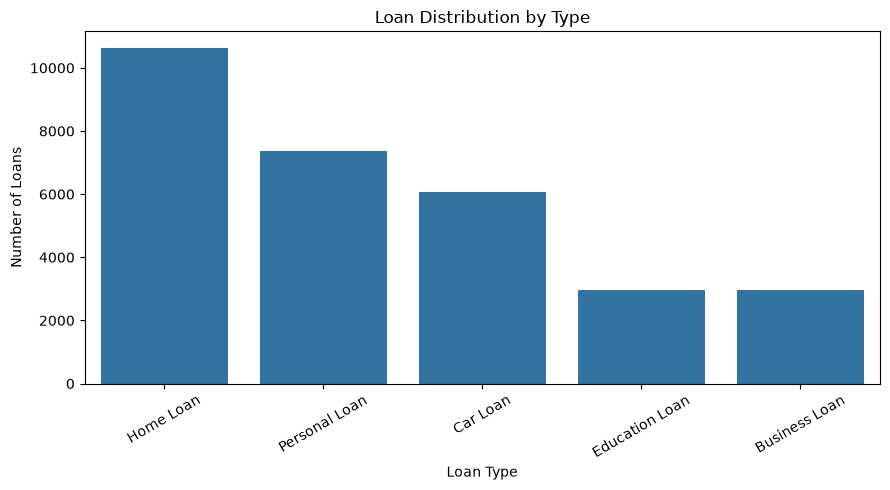

In [15]:
loan_type_counts = loans["loan_type"].value_counts()

display(loan_type_counts.to_frame("loan_count"))

plt.figure(figsize=(9, 5))
sns.countplot(data=loans, x="loan_type", order=loan_type_counts.index)
plt.title("Loan Distribution by Type")
plt.xlabel("Loan Type")
plt.ylabel("Number of Loans")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Top Product: Home Loans lead significantly (~10,600 loans), serving as the primary driver of lending demand.   
Secondary Drivers: Personal Loans (~7,400) and Car Loans (~6,100) form a strong middle tier for consumer financing.   

Lower Volume Categories: Education Loans and Business Loans sit at the bottom, tied at ~3,000 loans each.   

Main Takeaway: Prioritize Home Loans for core revenue growth, while offering targeted promotions to boost adoption in underrepresented segments like Business and Education Loans. 

In [16]:
default_count = (loans["default_flag"] == 1).sum()
total_loans = len(loans)

print("Total loans:", f"{total_loans:,}")
print("Defaulted loans:", f"{default_count:,}")
print("Default rate:", f"{default_count / total_loans * 100:.2f}%")

Total loans: 30,000
Defaulted loans: 0
Default rate: 0.00%


In [17]:
# Count loans and defaults by loan type
default_by_type = loans.groupby("loan_type").agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", lambda x: (x.astype(str).str.strip().str.lower() == "yes").sum())
)

# Calculate default rate
default_by_type["default_rate_pct"] = (
    default_by_type["defaulted_loans"] /
    default_by_type["total_loans"] * 100
).round(2)

display(default_by_type.sort_values("default_rate_pct", ascending=False))

,total_loans,defaulted_loans,default_rate_pct
loan_type,,,
Business Loan,2962,167,5.64
Car Loan,6082,338,5.56
Personal Loan,7366,407,5.53
Home Loan,10627,556,5.23
Education Loan,2963,149,5.03


In [18]:
print(loans["default_flag"].value_counts(dropna=False))

default_flag
No     28383
Yes     1617
Name: count, dtype: int64


count    30000.00
mean       688.96
std         82.97
min        324.00
25%        632.00
50%        690.00
75%        748.00
max        850.00
Name: credit_score, dtype: float64


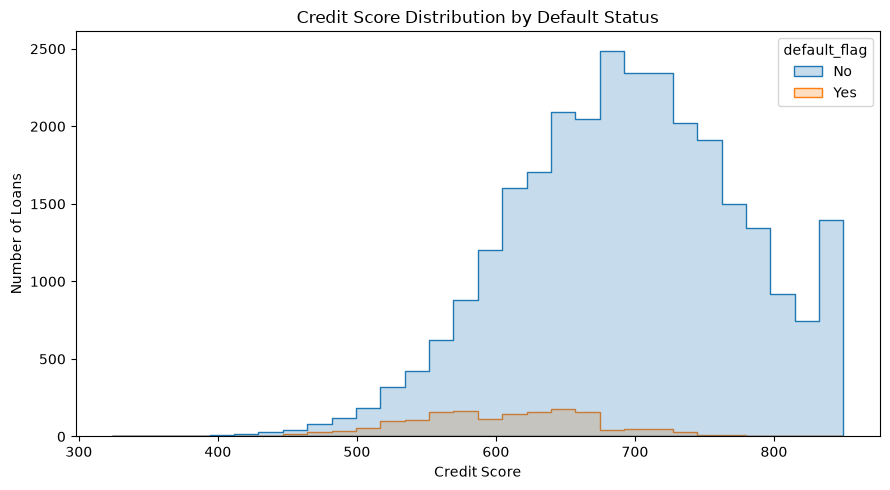

In [19]:
print(loans["credit_score"].describe().round(2))

plt.figure(figsize=(9, 5))
sns.histplot(
    data=loans,
    x="credit_score",
    hue="default_flag",
    bins=30,
    element="step"
)
plt.title("Credit Score Distribution by Default Status")
plt.xlabel("Credit Score")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.show()